In [331]:
import math
import torch
from torch import nn
from d2l import torch as d2l

$$\begin{aligned} p_{i, 2j} &= \sin\left(\frac{i}{10000^{2j/d}}\right),\\p_{i, 2j+1} &= \cos\left(\frac{i}{10000^{2j/d}}\right).\end{aligned}$$

In [332]:
"""位置编码"""
class PositionalEncoding(nn.Module):
    def __init__(self, num_hiddens, dropout, max_len=1000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(dropout)
        # batch设为1，因为位置编码是不依赖于batch_size的，之后可以使用广播机制进行相加
        self.P = torch.zeros((1, max_len, num_hiddens))
        X = torch.arange(max_len, dtype = torch.float32).reshape(
            -1, 1) / torch.pow(10000, torch.arange(
            0, num_hiddens, 2, dtype=torch.float32) / num_hiddens)
        self.P[:, :, 0::2] = torch.sin(X)
        self.P[:, :, 1::2] = torch.cos(X)

    def forward(self, X):
        # X 的形状为 (batch_size, seq_len, num_hiddens)
        # self.P[:, X.shape[1], :] 的形状为 (1, seq_len, num_hiddens)
        # 这里相加使用的使广播机制
        X = X + self.P[:, X.shape[1], :].to(X.device)
        return self.dropout(X)

In [333]:
""" 序列掩码 """
def sequence_mask(X, valid_len, value=0):
    # 获取特征维度
    maxlen = X.size(1)
    # torch.arange((maxlen)) -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
    # torch.arange((maxlen))[None, :] -> [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]
    # valid_len -> [4, 6]
    # valid_len[:, None] -> [[4], [6]]
    # < 比较使用的是广播的机制
    # torch.arange((maxlen))[None, :] -> [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
    #                                     [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]
    # valid_len[:, None] -> [[4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
    #                        [6, 6, 6, 6, 6, 6, 6, 6, 6, 6]]
    # [[ True,  True,  True,  True, False, False, False, False, False, False],
    #  [ True,  True,  True,  True,  True,  True, False, False, False, False]]
    mask = torch.arange((maxlen), dtype=torch.float32,
                        device=X.device)[None, :] < valid_len[:, None]
    # 对得到的结果进行一个反转，使需要修改的项为True，不需要修改的项为False
    X[~mask] = value
    return X

"""掩码softmax"""
def masked_softmax(X, valid_lens=None):
    # 初始 X 的形状为 (batch_size, seq_len, Embedding_size)
    if valid_lens is None:
        return nn.functional.softmax(X, dim=-1)
    else:
        shape = X.shape
        # 将valid_lens扩展为与X相同的形状
        if valid_lens.dim() == 1:
            valid_lens = torch.repeat_interleave(valid_lens, shape[1])
        else:
            valid_lens = valid_lens.reshape(-1)
        # 这里暂时将 X 重置为 (batch_size * seq_len, Embedding_size) 的形状
        # 然后对每个样本进行掩码操作
        # 最后将结果重置为 (batch_size, seq_len, Embedding_size) 的形状
        # 因为 softmax 操作在最后一个维度上进行
        X = sequence_mask(X.reshape(-1, shape[-1]), valid_lens, value = -1e6)
        return nn.functional.softmax(X.reshape(shape), dim=-1)

$$a(\mathbf q, \mathbf k) = \mathbf{q}^\top \mathbf{k}  /\sqrt{d}.$$

In [334]:
"""缩放点积注意力机制"""
class ScaleDotProductAttention(nn.Module):
    def __init__(self, dropout, **kwargs):
        super(ScaleDotProductAttention, self).__init__(**kwargs)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query, key, value, valid_lens=None):
        d = query.shape[-1]
        scores = torch.bmm(query, key.transpose(-2, -1) / math.sqrt(d))   
        attn_weights = self.dropout(masked_softmax(scores, valid_lens))
        attn_outputs = torch.bmm(attn_weights, value)
        return attn_outputs

In [335]:
""" 为了计算多头注意力，改变形状 """
def transpose_qkv(X, num_heads):
    # 输入X的形状:(batch_size，查询或者“键－值”对的个数，num_hiddens)
    # 输出X的形状:(batch_size，查询或者“键－值”对的个数，num_heads， num_hiddens/num_heads)
    X = X.reshape(X.shape[0], X.shape[1], num_heads, -1)
    # 输出X的形状:(batch_size，num_heads， 查询或者“键－值”对的个数， num_hiddens/num_heads)
    X = X.permute(0, 2, 1, 3)
    # 最终输出的形状:(batch_size*num_heads， 查询或者“键－值”对的个数， num_hiddens/num_heads)
    return X.reshape(-1, X.shape[2], X.shape[3])

""" 将多个头的输出拼接起来 """
def transpose_output(X, num_heads):
    # transpose_qkv的逆操作
    # 输入X的形状:(batch_size*num_heads， 查询或者“键－值”对的个数， num_hiddens/num_heads)
    # 输出X的形状:(batch_size，num_heads， 查询或者“键－值”对的个数， num_hiddens/num_heads)
    X = X.reshape(-1, num_heads, X.shape[1], X.shape[2])
    # 输出X的形状:(batch_size，查询或者“键－值”对的个数，num_heads， num_hiddens/num_heads)
    X = X.permute(0, 2, 1, 3)
    # 最终输出的形状:(batch_size，查询或者“键－值”对的个数， num_hiddens)
    return X.reshape(X.shape[0], X.shape[1], -1)

In [336]:
""" 多头注意力机制 """
class MultiHeadAttention(nn.Module):
    def __init__(self, query_size, key_size, value_size, num_hiddens, num_heads, dropout, bias=False, **kwargs):
        super(MultiHeadAttention, self).__init__(**kwargs)
        self.num_heads = num_heads
        self.attention = ScaleDotProductAttention(dropout)
        self.wq = nn.Linear(query_size, num_hiddens, bias = bias)
        self.wk = nn.Linear(key_size, num_hiddens, bias = bias)
        self.wv = nn.Linear(value_size, num_hiddens, bias = bias)
        self.wo = nn.Linear(num_hiddens, num_hiddens, bias = bias)

    def forward(self, query, key, value, valid_lens=None):
        """ 
            为什么需要转换到(batch_size * num_heads，查询或者“键－值”对的个数，num_hiddens / num_heads)，
            而不是(batch_size ，num_heads，查询或者“键－值”对的个数，num_hiddens / num_heads)
            因为在后续计算注意力打分函数时，torch.bmm 要求 3D 输入
        """
        # query/key/value: (batch_size，查询或者“键－值”对的个数，num_hiddens)
        # valid_lens: (batch_size，查询的个数)
        # 变换后
        # query/key/value: (batch_size * num_heads，查询或者“键－值”对的个数，num_hiddens / num_heads)
        query = transpose_qkv(self.wq(query), self.num_heads)
        key = transpose_qkv(self.wk(key), self.num_heads)
        value = transpose_qkv(self.wv(value), self.num_heads)
        # valid_lens: (batch_size * num_heads，查询的个数)
        if valid_lens is not None:
            valid_lens = torch.repeat_interleave(valid_lens, self.num_heads, dim=0)
        # 使用多头注意力机制提取上下文信息
        # output: (batch_size * num_heads，seq_len，num_hiddens / num_heads)
        output = self.attention(query, key, value, valid_lens)
        # 合并多头注意力机制的输出
        # output_catout: (batch_size，seq_len，num_hiddens)
        output_catout = transpose_output(output, self.num_heads)
        # 将多个注意力头提取的异构信息进行加权融合与维度重整
        return self.wo(output_catout)

In [337]:
num_hiddens, num_heads = 100, 5
attention = MultiHeadAttention(num_hiddens, num_hiddens, num_hiddens,
                               num_hiddens, num_heads, 0.5)

In [338]:
# 多头注意力输出的形状是（batch_size，num_queries，num_hiddens）
batch_size, num_queries = 2, 4
num_kvpairs, valid_lens =  6, torch.tensor([3, 2])
X = torch.ones((batch_size, num_queries, num_hiddens))
Y = torch.ones((batch_size, num_kvpairs, num_hiddens))
attention(X, Y, Y, valid_lens).shape

torch.Size([2, 4, 100])

In [339]:
""" 层归一化 """
class LayerNorm(nn.Module):
    def __init__(self, norm_shape, dropout, **kwargs):
        super(LayerNorm, self).__init__(**kwargs)
        self.dropout = nn.Dropout(dropout)
        self.layer_norm = nn.LayerNorm(norm_shape)

    def forward(self, X, Y):
        return self.layer_norm(self.dropout(Y) + X)

In [340]:
""" 前馈网络 """
class FeedForwardNetwork(nn.Module):
    def __init__(self, ffn_num_inputs, ffn_num_hiddens, ffn_num_outputs, **kwargs):
        super(FeedForwardNetwork, self).__init__(**kwargs)
        self.dense1 = nn.Linear(ffn_num_inputs, ffn_num_hiddens)
        self.relu = nn.ReLU()
        self.dense2 = nn.Linear(ffn_num_hiddens, ffn_num_outputs)

    def forward(self, X):
        return self.dense2(self.relu(self.dense1(X)))


In [341]:
""" 编码器块 """
class EncoderBlock(nn.Module):
    def __init__(self, query_size, key_size, value_size, num_hiddens, num_heads, norm_shape, 
                 ffn_num_inputs, ffn_num_hiddens, dropout, **kwargs):
        super(EncoderBlock, self).__init__(**kwargs)
        self.attention = MultiHeadAttention(query_size, key_size, value_size, num_hiddens, num_heads, dropout)
        self.layer_norm1 = LayerNorm(norm_shape, dropout)
        self.ffn = FeedForwardNetwork(ffn_num_inputs, ffn_num_hiddens, num_hiddens)
        self.layer_norm2 = LayerNorm(norm_shape, dropout)

    def forward(self, X, valid_lens):
        Y = self.layer_norm1(X, self.attention(X, X, X, valid_lens))
        return self.layer_norm2(Y, self.ffn(Y))

``` text
输入 Embedding + Position
        │
        ▼
Multi-Head Attention
（和其他 Token 交换信息）
        │
Residual + LayerNorm
（保留原始信息，稳定数值）
        │
Feed Forward Network
（每个 Token 独立进行深度特征提取）
        │
Residual + LayerNorm
（再次保留信息并稳定数值）
        │
输出到下一层 Encoder
```

In [342]:
class TransformerEncoder(nn.Module):
    def __init__(self, vocab_size, query_size, key_size, value_size, num_hiddens, num_heads, norm_shape, 
                 ffn_num_inputs, ffn_num_hiddens,  num_layers, dropout, **kwargs):
        super(TransformerEncoder, self).__init__(**kwargs)
        self.num_hiddens = num_hiddens
        self.embedding = nn.Embedding(vocab_size, num_hiddens)
        self.position_embedding = PositionalEncoding(num_hiddens, dropout)
        self.blks = nn.Sequential()
        for i in range(num_layers):
            self.blks.add_module('block' + str(i), 
               EncoderBlock(query_size, key_size, value_size, num_hiddens, num_heads,
                            norm_shape, ffn_num_inputs, ffn_num_hiddens, dropout))

    def forward(self, X, valid_lens):
        X = self.position_embedding(self.embedding(X) * math.sqrt(self.num_hiddens))
        for i, blk in enumerate(self.blks):
            X = blk(X, valid_lens)
        return X

In [343]:
""" 解码器块 """
class DecoderBlock(nn.Module):
    def __init__(self, i, query_size, key_size, value_size, num_hiddens, num_heads, norm_shape,
                 ffn_num_inputs, ffn_num_hiddens, dropout, **kwargs):
        super(DecoderBlock, self).__init__(**kwargs)
        self.i = i      # 第 i 个解码器块
        self.mask_attention = MultiHeadAttention(query_size, key_size, value_size, num_hiddens, num_heads, dropout)
        self.layer_norm1 = LayerNorm(norm_shape, dropout)
        self.cross_attention = MultiHeadAttention(query_size, key_size, value_size, num_hiddens, num_heads, dropout)
        self.layer_norm2 = LayerNorm(norm_shape, dropout)
        self.ffn = FeedForwardNetwork(ffn_num_inputs, ffn_num_hiddens, num_hiddens)
        self.layer_norm3 = LayerNorm(norm_shape, dropout)

    def forward(self, X, state):
        encoder_output, encoder_valid_lens = state[0], state[1]
        # state[2][self.i] 是解码器块的键值对
        # 如果是第一个时间步，则直接用当前输入X 用作Key和Value
        if state[2][self.i] is None:
            key_values = X
        else:   
            # 否则，将当前输入 X 与之前的键值对拼接起来
            # X中是当前时间步的信息，而state[2][self.i]中是之前时间步的信息
            # 时间步 1：key_values = [X₁]
            # 时间步 2：key_values = [X₁, X₂]
            # 时间步 3：key_values = [X₁, X₂, X₃]
            # 时间步 4：key_values = [X₁, X₂, X₃, X₄]
            key_values = torch.cat((state[2][self.i], X), axis=1)
        # 更新key_values
        state[2][self.i] = key_values
        if self.training:
            batch_size, num_steps, _ = X.shape
            # 生成一个长度为 batch_size 的向量，每个元素为 num_steps
            dev_valid_lens = torch.arange(1, num_steps+1, device = X.device).repeat(batch_size, 1)
        else:
            dev_valid_lens = None

        Y = self.layer_norm1(X, self.mask_attention(X, key_values, key_values, dev_valid_lens))
        Z = self.layer_norm2(Y, self.cross_attention(Y, encoder_output, encoder_output, encoder_valid_lens))
        return self.layer_norm3(Z, self.ffn(Z)), state

``` text
目标序列 Embedding + Position
        │
        ▼
Masked Multi-Head Attention
（目标序列内部交换信息，只能看当前位置及之前的 Token）
        │
Residual + LayerNorm
（保留原始信息，稳定数值）
        │
        ▼
Cross Multi-Head Attention
（查询 Encoder 输出，从源序列获取相关信息）
        │
Residual + LayerNorm
（融合源序列信息，同时保留 Decoder 原有信息）
        │
        ▼
Feed Forward Network
（每个 Token 独立进行非线性特征提取）
        │
Residual + LayerNorm
（再次保留信息并稳定数值）
        │
        ▼
输出到下一层 Decoder
```

In [344]:
"""Transformer解码器"""
class TransformerDecoder(nn.Module):
    def __init__(self, vocab_size, query_size, key_size, value_size, num_hiddens, num_heads,
                 norm_shape, ffn_num_input, ffn_num_hiddens, num_layers, dropout, **kwargs):
        super(TransformerDecoder, self).__init__(**kwargs)
        self.num_hiddens = num_hiddens
        self.num_layers = num_layers
        self.embedding = nn.Embedding(vocab_size, num_hiddens)
        self.pos_encoding = PositionalEncoding(num_hiddens, dropout)
        self.blks = nn.Sequential()
        for i in range(num_layers):
            self.blks.add_module("block"+str(i),
                DecoderBlock(i, query_size, key_size, value_size, num_hiddens, num_heads, 
                             norm_shape, ffn_num_input, ffn_num_hiddens, dropout)) 
        self.dense = nn.Linear(num_hiddens, vocab_size)

    def init_state(self, enc_outputs, enc_valid_lens, *args):
        return [enc_outputs, enc_valid_lens, [None] * self.num_layers]

    def forward(self, X, state):
        X = self.pos_encoding(self.embedding(X) * math.sqrt(self.num_hiddens))
        for i, blk in enumerate(self.blks):
            X, state = blk(X, state)
        return self.dense(X), state


In [345]:
"""Transformer编码解码器"""
class  EncoderDecoder(nn.Module):
    def __init__(self, encoder, decoder, **kwargs):
        super(EncoderDecoder, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, enc_inputs, dec_inputs, *args):
        enc_outputs = self.encoder(enc_inputs, *args)
        dec_state = self.decoder.init_state(enc_outputs, *args)
        return self.decoder(dec_inputs, dec_state)

loss 0.031, 2185.7 tokens/sec on cuda:0


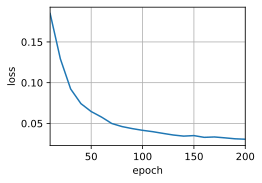

In [346]:
query_size, key_size, value_size = 32, 32, 32
num_hiddens, num_heads, norm_shape, num_layers = 32, 4, 32, 2
ffn_num_input, ffn_num_hiddens = 32, 32
dropout = 0.1
batch_size , num_steps = 64, 10
num_epochs, lr, device = 200, 0.005, d2l.try_gpu()

train_iter, src_vocab, tgt_vocab = d2l.load_data_nmt(batch_size, num_steps)

encoder = TransformerEncoder(
    len(src_vocab), query_size, key_size, value_size, num_hiddens, norm_shape, 
    ffn_num_input, ffn_num_hiddens, num_heads, num_layers, dropout
)

decoder = TransformerDecoder(
    len(tgt_vocab), query_size, key_size, value_size, num_hiddens, norm_shape, 
    ffn_num_input, ffn_num_hiddens, num_heads, num_layers, dropout
)

net = EncoderDecoder(encoder, decoder)
d2l.train_seq2seq(net, train_iter, lr, num_epochs, tgt_vocab, device)